# 3.0 Error analysis of the final model (training set)

**Purpose.** Step 25 of the lifecycle: before the test set is unlocked, find out *where* and *for whom* the chosen model is wrong. This is the last point where findings can still send us back to cleaning or features; once the test set has been looked at, they can't.

**Model.** The final model chosen in [docs/model-comparison.md](../docs/model-comparison.md) (gradient boosting), with its inputs and settings read from `models/tuned.json`.

**Data.** The **training set only**. Every listing is predicted by a model trained on the other 4 folds, never on itself (*out-of-fold predictions*, same grouped folds as the comparison), so the errors here are honest without touching the test set.

**Sections.** 1 Setup · 2 Overall · 3 Errors by price level · 4 Errors by phone age and condition · 5 Seller type and region (fairness) · 6 Largest errors · 7 What drives the predictions · 8 Summary and decision

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.inspection import permutation_importance

from priced_right import evaluate, features, pipelines
from priced_right.models import TUNED_PATH
from priced_right.split import load_train

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.grid": True, "grid.color": "#e6e5e1", "axes.edgecolor": "#c3c2b7", "axes.axisbelow": True})
pd.set_option("display.max_columns", 30, "display.width", 140)

tuned = json.loads(TUNED_PATH.read_text(encoding="utf-8"))
name = tuned["final_model"]
columns, params = tuned["models"][name]["columns"], tuned["models"][name]["params"]
print(f"final model: {name}\ninputs: {columns}\nsettings: {params}")

train = load_train()
X, y, groups = features.build(train), features.target(train), train["relisting_group"]
model = pipelines.build(name, columns, **params)

# Out-of-fold predictions: each listing predicted by a model that never saw it
oof = evaluate.out_of_fold_predictions(model, X, y, groups)
oof_baseline = evaluate.out_of_fold_predictions(pipelines.baseline(), X, y, groups)

df = train.assign(predicted=features.to_price(oof), log_error=oof - y)
df["pct_error"] = (df["predicted"] - df["price_eur"]) / df["price_eur"]
df["baseline_log_error"] = oof_baseline - y


def error_table(by):
    """Per group: listings, RMSLE of the model and the baseline, typical over/under-pricing, median % error."""
    g = df.groupby(by, observed=True)
    return pd.DataFrame({
        "listings": g.size(),
        "RMSLE": g["log_error"].apply(lambda e: np.sqrt((e ** 2).mean())),
        "RMSLE baseline": g["baseline_log_error"].apply(lambda e: np.sqrt((e ** 2).mean())),
        "bias": g["log_error"].median().apply(np.expm1),  # + = model predicts too high
        "median % error": g["pct_error"].apply(lambda e: e.abs().median()),
    })


def show(table):
    return table.style.format({"RMSLE": "{:.3f}", "RMSLE baseline": "{:.3f}", "bias": "{:+.0%}", "median % error": "{:.0%}"})

final model: Gradient boosting
inputs: ['release_year', 'tier', 'condition_level', 'storage_log2', 'seller_type', 'mentions_damage']
settings: {'l2_regularization': 0.0, 'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 4, 'min_samples_leaf': 20}


## 2. Overall

**What:** the final model's out-of-fold scores next to the baseline, and predicted vs actual price for every training listing.
**Why:** the overall numbers should match the model comparison; the scatter shows whether errors are spread evenly or concentrated somewhere.

,rmsle,mae_eur,median_ape
final model,0.284,47 €,13.5%
baseline,0.370,56 €,16.7%


share of the variation in log price explained (R²): 0.90


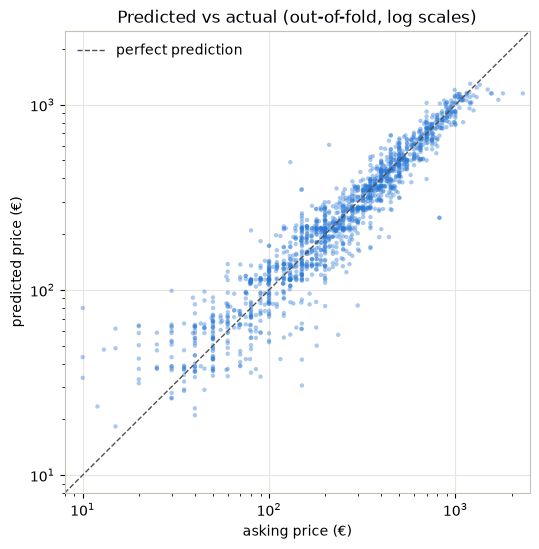

In [2]:
overall = pd.DataFrame({"final model": evaluate.scores(y, oof), "baseline": evaluate.scores(y, oof_baseline)}).T
r2 = 1 - ((oof - y) ** 2).sum() / ((y - y.mean()) ** 2).sum()
display(overall.style.format({"rmsle": "{:.3f}", "mae_eur": "{:.0f} €", "median_ape": "{:.1%}"}))
print(f"share of the variation in log price explained (R²): {r2:.2f}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(df["price_eur"], df["predicted"], s=10, alpha=0.4, color=BLUE, edgecolors="none")
ax.plot([8, 2500], [8, 2500], color="#52514e", linewidth=1, linestyle="--", label="perfect prediction")
ax.set(xscale="log", yscale="log", xlim=(8, 2500), ylim=(8, 2500), xlabel="asking price (€)", ylabel="predicted price (€)",
       title="Predicted vs actual (out-of-fold, log scales)")
ax.legend(frameon=False, loc="upper left")
plt.show()

**Takeaway:** on listings it never saw, the final model scores RMSLE 0.284, MAE 47 € and a median error of 13.5%, vs 0.370 / 56 € / 16.7% for the baseline: the same as in the model comparison. It explains 90% of the variation in log price.

The points follow the diagonal closely from about 100 € up, but spread widely below that. The model also pulls both extremes towards the middle: very cheap phones are predicted too high, and the few listings above 1,500 € (the newest Pro Max) too low. Tree-based models can't predict beyond the prices they've seen for similar phones, so this is expected.

## 3. Errors by price level

**What:** errors for five equal-sized groups of listings, from the cheapest to the most expensive.
**Why:** a pricing tool that's reliable for 800 € phones but not for 50 € ones should say so. *Bias* is the typical over- (+) or under-pricing (−).

,listings,RMSLE,RMSLE baseline,bias,median % error
price band,,,,,
"(9.0, 100.0]",322,0.413,0.594,+16%,26%
"(100.0, 199.0]",326,0.319,0.366,+4%,18%
"(199.0, 320.0]",315,0.253,0.329,-5%,12%
"(320.0, 500.0]",333,0.189,0.215,-1%,10%
"(500.0, 2299.0]",306,0.171,0.202,-3%,8%


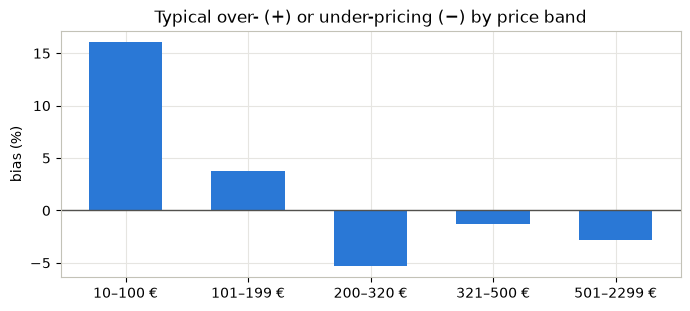

In [3]:
df["price band"] = pd.qcut(df["price_eur"], 5, precision=0)
bands = error_table("price band")
display(show(bands))

fig, ax = plt.subplots(figsize=(8, 3.2))
labels = [f"{int(i.left) + 1}–{int(i.right)} €" for i in bands.index]
ax.bar(labels, bands["bias"] * 100, color=BLUE, width=0.6)
ax.axhline(0, color="#52514e", linewidth=1)
ax.set(title="Typical over- (+) or under-pricing (−) by price band", ylabel="bias (%)")
plt.show()

**Takeaway:** errors shrink as prices rise, from RMSLE 0.41 and a 26% median miss for phones under 100 € to 0.17 and 8% above 500 €. Phones under 100 € are typically priced **16% too high**; every band above 200 € is within ±5%. The model beats the baseline in every band.

**For the app:** estimates for cheap, old phones are rough, and the price range (step 27) should show that.

## 4. Errors by phone age and condition

**What:** errors by launch period and by Tori condition level, compared with the baseline.
**Why:** the EDA showed old phones and broken phones price erratically. This checks how much that hurts the model.

,listings,RMSLE,RMSLE baseline,bias,median % error
launched,,,,,
2016 or earlier,99,0.514,0.650,-4%,33%
2017–19,333,0.347,0.488,+0%,19%
2020–22,719,0.265,0.335,-0%,14%
2023–26,451,0.167,0.196,-1%,9%


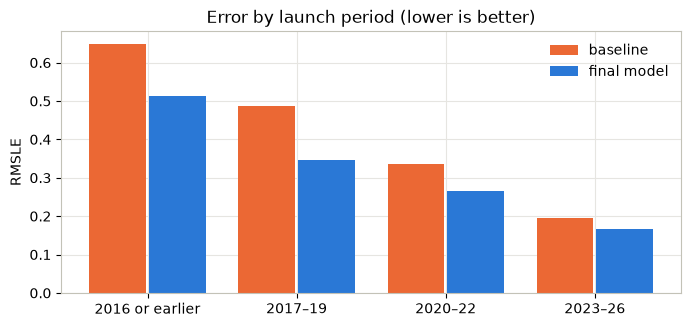

,listings,RMSLE,RMSLE baseline,bias,median % error
condition,,,,,
Vaatii korjausta,37,0.633,1.034,+15%,47%
Kohtalainen,118,0.390,0.570,-4%,19%
Hyvä,762,0.279,0.334,-2%,15%
Kuin uusi,554,0.232,0.288,-0%,10%
Uusi,82,0.202,0.188,+2%,10%


In [4]:
df["launched"] = pd.cut(df["release_year"], [2000, 2016, 2019, 2022, 2026], labels=["2016 or earlier", "2017–19", "2020–22", "2023–26"])
by_age = error_table("launched")
display(show(by_age))

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(by_age))
ax.bar(x - 0.2, by_age["RMSLE baseline"], width=0.38, color=ORANGE, label="baseline")
ax.bar(x + 0.2, by_age["RMSLE"], width=0.38, color=BLUE, label="final model")
ax.set_xticks(x, labels=by_age.index)
ax.set(title="Error by launch period (lower is better)", ylabel="RMSLE")
ax.legend(frameon=False)
plt.show()

order = ["Vaatii korjausta", "Kohtalainen", "Hyvä", "Kuin uusi", "Uusi"]
display(show(error_table("condition").loc[order]))

**Takeaway:** the same pattern by age. Phones launched in 2023 or later are typically predicted within 9%; those from 2016 or earlier within 33%, because they have few listings and erratic prices (EDA 4.1). Bias is near zero for every period, so the model isn't systematically wrong for any age, just less precise for old phones.

By condition, **needs repair** is the weak spot: only 37 listings, a median miss of 47%, and priced 15% too high. How broken a phone is varies enormously, and one condition level can't capture that. The model is still far better than the baseline there (RMSLE 0.63 vs 1.03).

## 5. Seller type and region (fairness)

**What:** errors and bias for private sellers vs retailers, and for each region with at least 20 listings (smaller regions are grouped).
**Why:** the ML plan requires checking both groups. A model that systematically over- or under-prices one group's phones would mislead those users. Region is not a model input, so any regional pattern comes from the phones sold there.

In [5]:
display(show(error_table("seller_type")))

counts = df["region"].value_counts()
df["region (20+ listings)"] = df["region"].where(df["region"].map(counts) >= 20, "other (fewer than 20)")
display(show(error_table("region (20+ listings)").sort_values("listings", ascending=False)))

,listings,RMSLE,RMSLE baseline,bias,median % error
seller_type,,,,,
private,1265,0.299,0.376,-0%,14%
retailer,337,0.222,0.347,-1%,10%


,listings,RMSLE,RMSLE baseline,bias,median % error
region (20+ listings),,,,,
Uusimaa,744,0.274,0.342,+1%,12%
Pirkanmaa,162,0.253,0.370,-0%,12%
Varsinais-Suomi,155,0.280,0.387,-1%,14%
Pohjanmaa,75,0.282,0.493,-7%,11%
Pohjois-Pohjanmaa,69,0.347,0.487,-5%,14%
Keski-Suomi,61,0.251,0.359,+3%,14%
Päijät-Häme,54,0.356,0.337,-8%,17%
Pohjois-Savo,37,0.208,0.268,-0%,12%
Kymenlaakso,36,0.413,0.461,+6%,23%


**Takeaway:**
- **Seller type:** no bias for either group (0% for private sellers, −1% for retailers). Private sellers' phones are harder to price (median miss 14% vs 10%) because their prices vary more.
- **Region:** errors differ between regions (RMSLE 0.19–0.41), but region isn't a model input, so the differences come from the phones and sellers in each region, and from small samples (most regions have 20–75 listings). Bias is within ±8% everywhere except Etelä-Karjala (+12%, 28 listings) and the grouped small regions (+12%, 8 listings).

No group stands out as systematically mispriced beyond what small samples explain. The test set checks this again, together with the coverage of the price ranges.

## 6. Largest errors

**What:** the listings the model gets most wrong in each direction, and three kinds of ads that stood out among them.
**Why:** big errors are where data problems hide. Each is either a data error (back to cleaning) or a real listing the inputs can't describe (a limitation to report).

In [6]:
# Ad text is kept out of the repository; this cell needs the local data/processed/iphones_text.csv
from priced_right.preprocess import load_text
ad_text = load_text().set_index("listing_id")
df["title"] = df["listing_id"].map(ad_text["title"])
df["description"] = df["listing_id"].map(ad_text["description"])

cols = ["exact_model", "storage_gb", "condition", "seller_type", "price_eur", "predicted", "title"]
print("Priced much higher than the model predicts:")
display(df.sort_values("log_error")[cols].head(6).round(0))
print("Priced much lower than the model predicts:")
display(df.sort_values("log_error")[cols].tail(6).round(0))

text = df["title"] + " " + df["description"]
kinds = {
    "sold for parts (varaosiksi / varaosina)": r"varaosiksi|varaosina|varaosia varten|varaosiks\b",
    "collector / antique (keräily, antiikki)": r"antiik|keräil|harvinai|collector",
    "several phones (kaksi / kolme ... iPhonea)": r"\b(?:kaksi|kolme)\s+(?:\w+\s+){0,2}iphone(?:a|ta)\b",
}
rows = []
for kind, pattern in kinds.items():
    hit = text.str.contains(pattern, case=False)
    rows.append({"kind": kind, "listings": int(hit.sum()), "bias": np.expm1(df.loc[hit, "log_error"].median()),
                 "RMSLE": np.sqrt((df.loc[hit, "log_error"] ** 2).mean())})
display(pd.DataFrame(rows).set_index("kind").style.format({"bias": "{:+.0%}", "RMSLE": "{:.3f}"}))

Priced much higher than the model predicts:


,exact_model,storage_gb,condition,seller_type,price_eur,predicted,title
1544,iPhone X,NaN,Vaatii korjausta,private,150,30.0,Iphone x 2
261,iPhone 5,NaN,Hyvä,private,235,57.0,Apple antiikki iPhone 5 ja suojakotelo
1203,iPhone XR,128.0,Kuin uusi,private,299,82.0,Apple iPhone XR älypuhelin 128 GB musta
1456,iPhone 11,64.0,Vaatii korjausta,private,180,50.0,Apple Iphone 11
1219,iPhone 3,16.0,NaN,private,150,42.0,Iphone 3 S 3G musta
1252,iPhone 11 Pro Max,64.0,Kuin uusi,retailer,820,245.0,"Apple iPhone 11 Pro Max 64 Gt, tähtiharmaa"


Priced much lower than the model predicts:


,exact_model,storage_gb,condition,seller_type,price_eur,predicted,title
316,iPhone 11,128.0,Kohtalainen,private,30,99.0,iPhone 11
1123,iPhone 6s,32.0,Kuin uusi,private,13,48.0,iPhone 6s 32gb
202,iPhone 15 Pro,128.0,Hyvä,private,130,490.0,Apple iPhone 15 Pro 128 GB musta varaosina
980,iPhone 4s,NaN,Hyvä,private,15,62.0,iPhone 4S
845,iPhone 5s,32.0,Kohtalainen,private,10,43.0,iphone 5S 32GB
452,iPhone SE,NaN,Hyvä,private,10,80.0,Apple iPhone SE puhelin


,listings,bias,RMSLE
kind,,,
sold for parts (varaosiksi / varaosina),13,-7%,0.739
"collector / antique (keräily, antiikki)",10,-44%,0.735
several phones (kaksi / kolme ... iPhonea),1,-79%,1.568


**Takeaway:** the biggest misses are listings the inputs can't describe:
- **Sold for parts** (13 ads, *varaosiksi*): e.g. an iPhone 15 Pro *varaosina* ("as parts") listed in *good* condition at 130 €; the model sees a good-condition 15 Pro and predicts 490 €. Most parts ads are already marked *needs repair* or *fair*, and the typical error on them is small (−7%), but single errors are large.
- **Collector ads** (10): an *antiikki* ("antique") iPhone 5 at 235 €, an original iPhone 3G at 150 €. Collectors price old phones far above what their age suggests; the model under-prices these by about 44%.
- **One multi-phone lot** that cleaning missed: *"Myydään kaksi vanhaa iphonea"* ("selling two old iPhones") at 150 €. `preprocess.py` catches "2 kpl" but not a number written as a word.
- **Ambitious or very cheap asks** with nothing unusual in the fields (an iPhone 11 Pro Max at 820 €, an iPhone 11 at 30 €).

Together these are under 2% of the training set. Catching them would need new text rules in cleaning, which risk new mistakes of their own for little gain.

**Decision: no changes; they are reported as limitations.**

## 7. What drives the predictions

**What:** *permutation importance*: how much worse the model gets (in RMSLE) when one input is shuffled, breaking its link to the price. Measured on each held-out fold with the model trained on the other folds, then averaged.
**Why:** it shows which inputs the model actually relies on, for the report and the app's explanation.

,RMSLE increase when shuffled
release_year,0.657
tier,0.121
condition_level,0.058
seller_type,0.045
storage_log2,0.038
mentions_damage,0.006


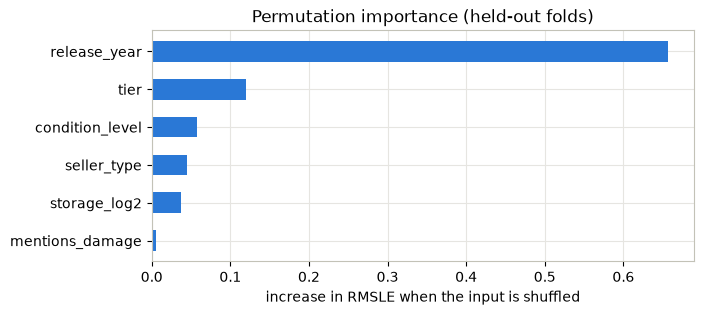

In [7]:
importances = []
for fit, held_out in evaluate.cv_splitter().split(X, groups=groups):
    fitted = clone(model).fit(X.iloc[fit], y[fit])
    result = permutation_importance(fitted, X.iloc[held_out][columns], y[held_out],
                                    scoring="neg_root_mean_squared_error", n_repeats=10, random_state=42)
    importances.append(result.importances_mean)
importance = pd.Series(np.mean(importances, axis=0), index=columns).sort_values()
display(importance.sort_values(ascending=False).round(3).rename("RMSLE increase when shuffled").to_frame())

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(importance.index, importance.values, color=BLUE, height=0.55)
ax.set(title="Permutation importance (held-out folds)", xlabel="increase in RMSLE when the input is shuffled")
plt.show()

**Takeaway:** launch year is by far the most important input (shuffling it raises RMSLE by 0.66), followed by product line (0.12), condition (0.06), seller type (0.05) and storage (0.04). The damage flag adds little (0.006): condition already carries most of that information.

This is also the order the app can use to explain an estimate: which phone first, then its condition and who's selling it.

## 8. Summary and decision

**How good is the model?** On training listings it never saw, its typical miss is 13.5% (47 € on average), vs 16.7% (56 €) for the baseline, and it explains 90% of the variation in log price.

| Less reliable | More reliable |
|:--|:--|
| Phones under 100 € (typical miss 26%, priced 16% too high) | Phones over 320 € (8–10%) |
| Launched 2016 or earlier (33%) | Launched 2023 or later (9%) |
| *Needs repair* (47%, 37 listings) | *Like new* and *new* (10%) |
| Ads for parts, collector ads, multi-phone lots | Retailer listings (10%) |

**Fairness (training set):** no bias by seller type; regional differences are within what small samples explain.

**Decision for step 25:** none of the findings calls for changing cleaning, features or the model. The weak spots are listings whose price depends on things the inputs can't capture, not errors in the pipeline. They go into the report as limitations, and the price ranges (step 27) should be wider where the model is less sure.

**Next: unlock the test set for the one final evaluation (step 26).**